Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.




In [182]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [183]:
df = pd.read_csv("/Users/tovancao/Ironhack/3_LAB/WEEK 5/amz_uk_price_prediction_dataset.csv")

In [184]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.


In [186]:
crosstab_result = pd.crosstab(df['category'],df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [220]:
total_prod = df['category'].value_counts()
total_prod

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [188]:
df.groupby("isBestSeller")['category'].value_counts()

isBestSeller  category                                        
False         Sports & Outdoors                                   835935
              Handmade Clothing, Shoes & Accessories               19215
              Bath & Body                                          19059
              Beauty                                               19010
              Birthday Gifts                                       18943
                                                                   ...  
True          Streaming Clients                                        1
              Tennis Shoes                                             1
              USB Hubs                                                 1
              Uninterruptible Power Supply Units & Accessories         1
              Water Coolers, Filters & Cartridges                      1
Name: count, Length: 556, dtype: int64

In [189]:
best_sellers = df[df['isBestSeller'] == 1]['category'].value_counts()

proportion_best_sellers = (best_sellers / total_prod) * 100

proportion_best_sellers_sorted = proportion_best_sellers.sort_values(ascending=False)

proportion_best_sellers_sorted


category
Grocery                           5.813467
Smart Home Security & Lighting    5.769231
Health & Personal Care            5.768628
Mobile Phone Accessories          4.247104
Power & Hand Tools                3.533895
                                    ...   
Snowboard Boots                        NaN
Toy Advent Calendars                   NaN
USB Gadgets                            NaN
Vases                                  NaN
eBook Readers & Accessories            NaN
Name: count, Length: 296, dtype: float64

Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.
Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [191]:
#chi square

In [192]:
from scipy.stats import chi2_contingency

# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(36540.20270061387, 0.0)

There is a significant association between category and best-seller as p value equals zero

In [194]:
#Cramér's V

In [195]:
from scipy.stats.contingency import association

association(crosstab_result, method="cramer")

0.1222829439760564

The Cramér's V value of 0.12 suggests a weak association between the two variables. 
Though statistically significant, the strength of this relationship is not very strong in practical terms.

In [197]:
#stack bar

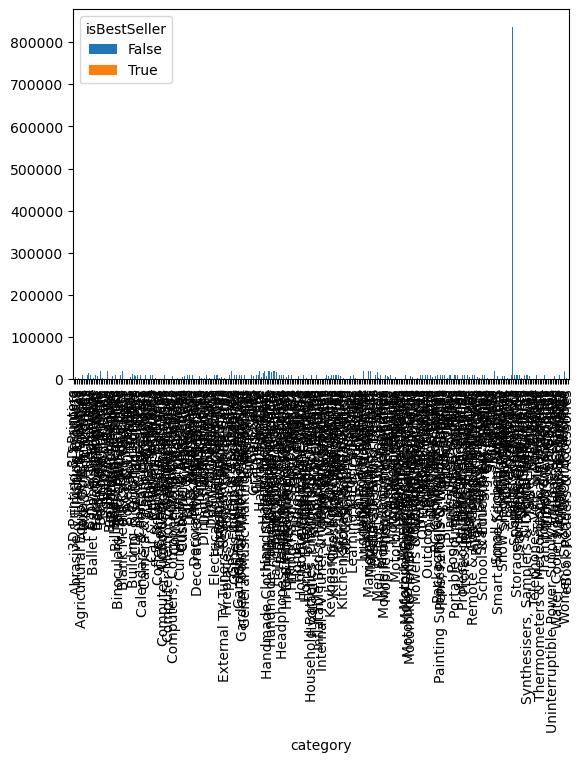

In [301]:
crosstab_result.plot(kind="bar", stacked=True);

Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.





Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.


In [201]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

In [202]:
data_series = df['price']  # replace 'ColumnName' with your specific column
outliers = tukeys_test_outliers(data_series)
print(outliers)

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64


In [334]:
df2 = df.iloc[~outliers.index,:] # ~ = NOT

Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.


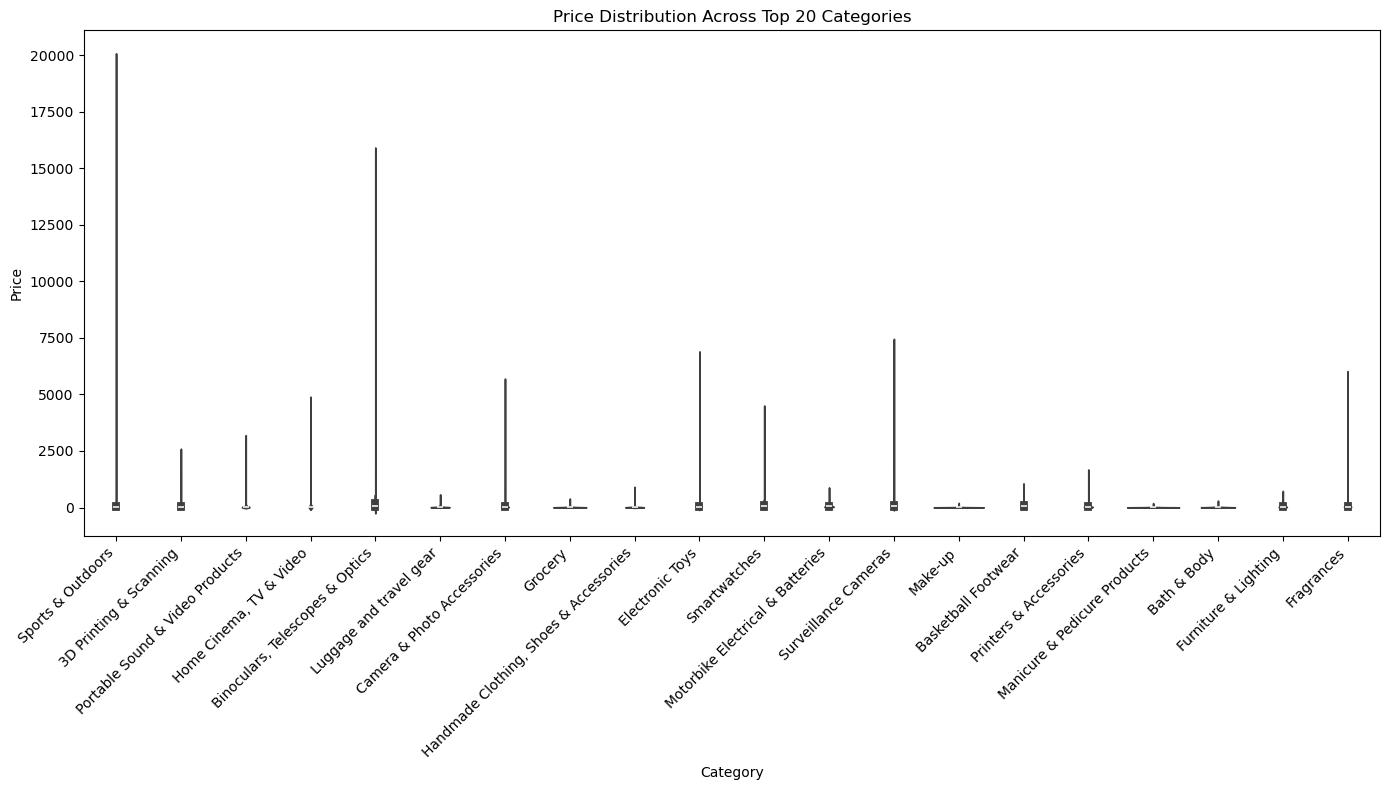

In [342]:
# Calculate the total count of products in each category
total_products = df2['category'].value_counts()

# Filter the top 20 categories
top_20_categories = total_products.head(20).index

# Filter the dataframe to include only the top 20 categories
df_top_20 = df2[df2['category'].isin(top_20_categories)]

# Set the size of the plot for better readability
plt.figure(figsize=(14, 8))

# Create the violin plot for price distribution across top 20 categories
sns.violinplot(x='category', y='price', data=df_top_20)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Add title and labels
plt.title('Price Distribution Across Top 20 Categories')
plt.xlabel('Category')
plt.ylabel('Price')

# Show the plot
plt.tight_layout()
plt.show()

Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

In [344]:
df2.groupby(['category'])['price'].mean()

category
3D Printing & Scanning                74.709600
Action Cameras                       121.915938
Adapters                               9.505926
Agricultural Equipment & Supplies     24.558966
Alexa Built-In Devices               213.392000
                                        ...    
Wind Instruments                     449.730000
Window Treatments                     13.792500
Women                                 21.826532
Women's Sports & Outdoor Shoes        66.000000
eBook Readers & Accessories           21.990000
Name: price, Length: 283, dtype: float64

Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


In [346]:
top_10_categories = total_products.head(10).index
top_10_categories

Index(['Sports & Outdoors', 'Bath & Body', 'Camera & Photo Accessories',
       'Handmade Clothing, Shoes & Accessories', 'Fragrances',
       'Luggage and travel gear', 'Binoculars, Telescopes & Optics',
       'Printers & Accessories', 'Portable Sound & Video Products',
       'Home Cinema, TV & Video'],
      dtype='object', name='category')

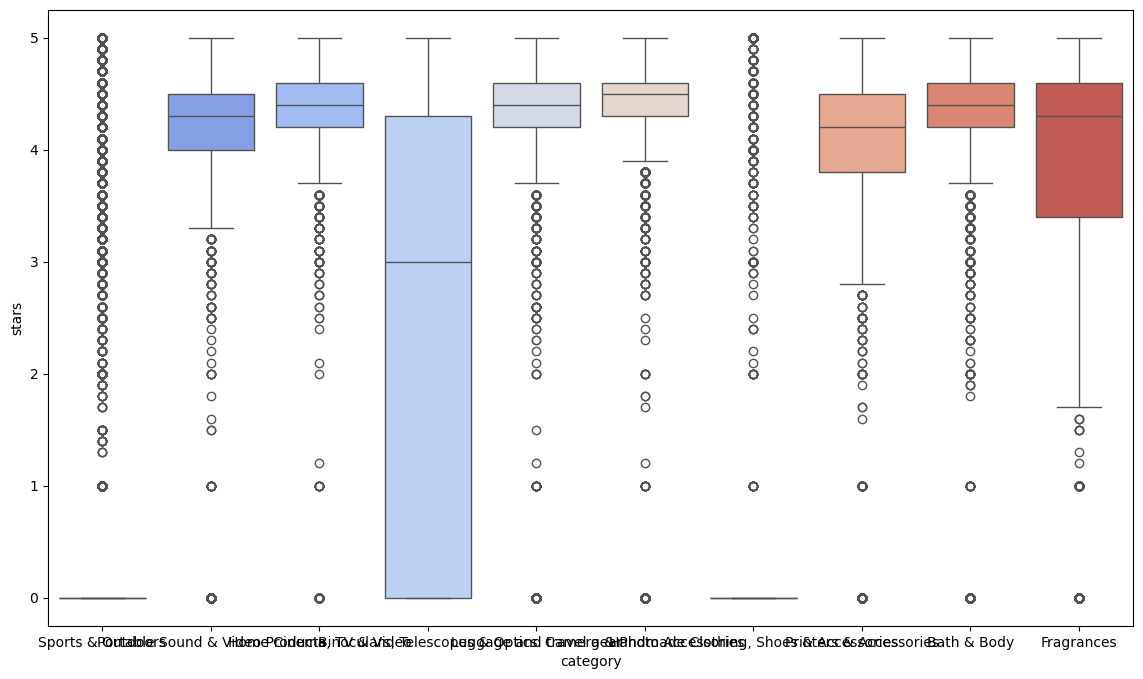

In [350]:
df_top_10 = df2[df2['category'].isin(top_10_categories)]

# Set the size of the plot for better readability
plt.figure(figsize=(14, 8))

sns.boxplot(data=df_top_10, x='category', y='stars', palette="coolwarm", hue='category', legend=False);

In [352]:
median_stars_by_category = df2.groupby(['category'])['stars'].median()

In [299]:
median_stars_by_category_sorted = median_stars_by_category.sort_values(ascending=False)
median_stars_by_category_sorted

category
Computer Memory                4.7
Hobbies                        4.6
Beer, Wine & Spirits           4.6
Laptop Accessories             4.6
Kids' Play Figures             4.6
                              ... 
KVM Switches                   0.0
Karaoke Equipment              0.0
Lab & Scientific Products      0.0
Laptops                        0.0
eBook Readers & Accessories    0.0
Name: stars, Length: 296, dtype: float64

We see that the categories with the highest median rating are not the categories with the most products.
Also in the top 10 categories most of the products are range above 3,5 and 4,5 stars

Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?



In [354]:
correlation = df2['price'].corr(df2['stars'])
correlation

-0.09842525447416527

Correlation is close to 0 implies little to no linear/monotonic correlation.

Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

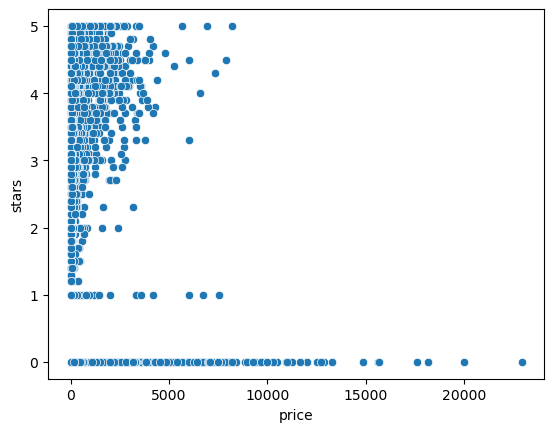

In [336]:
sns.scatterplot(data=df2, x='price', y='stars');

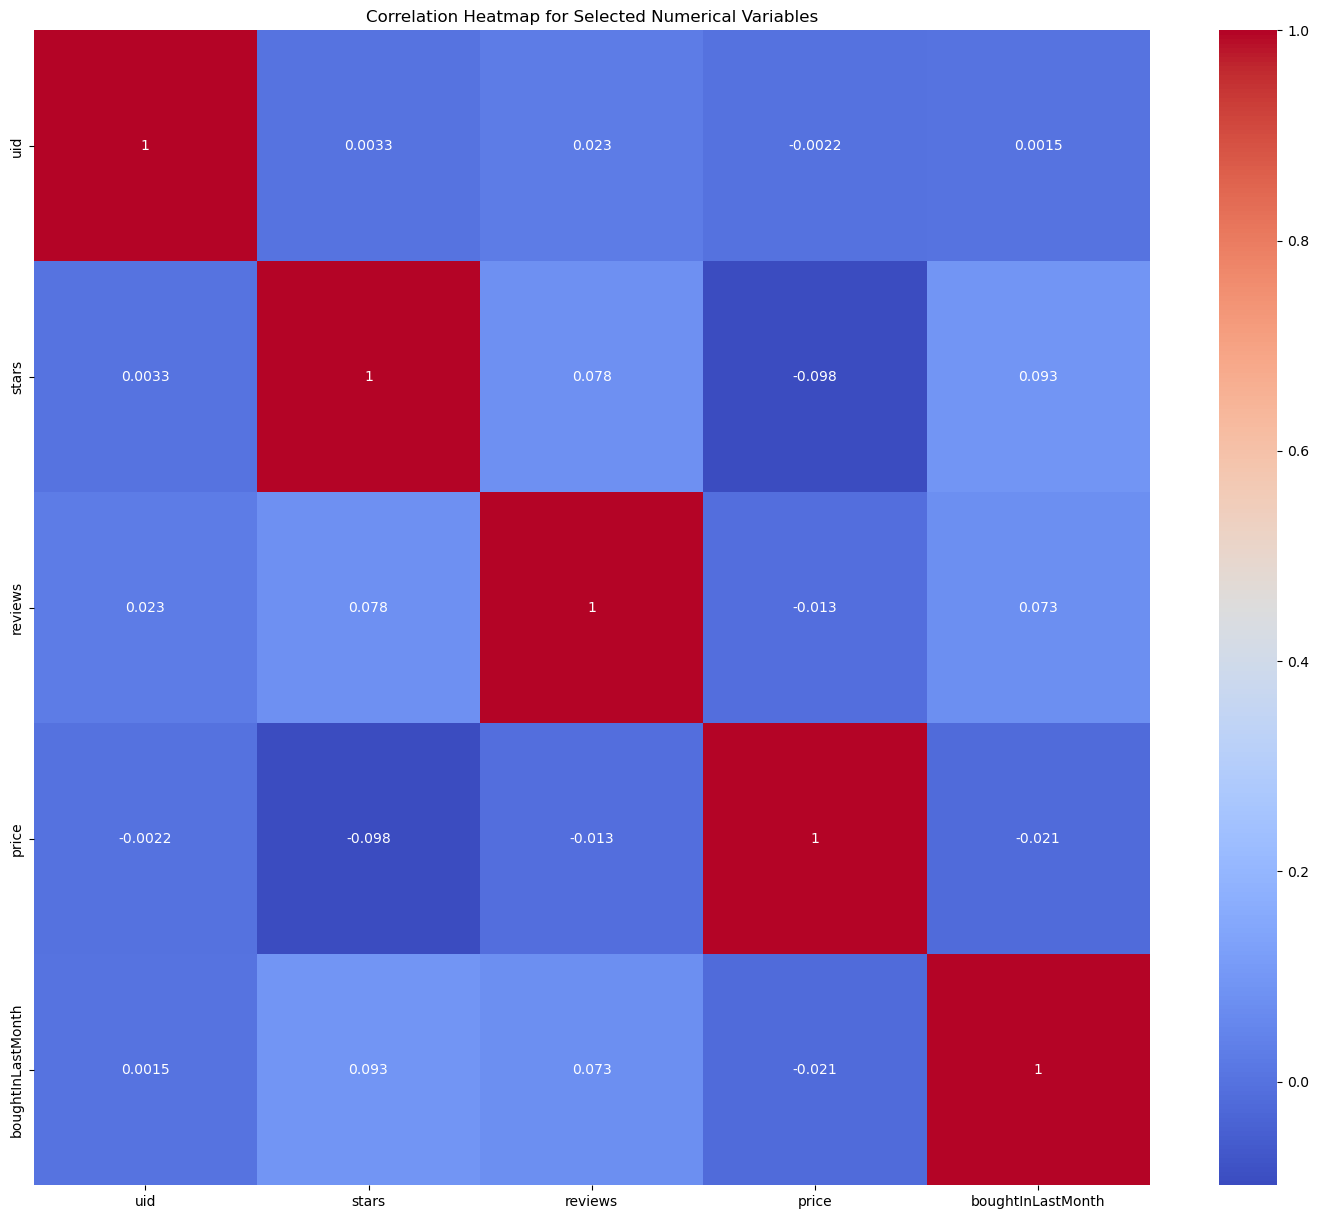

In [363]:
potential_categorical_from_numerical = df2.select_dtypes("number").loc[:, df2.select_dtypes("number").nunique() < 20]
df_numerical = df2.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

Strongest correlation is between price and ratings, price and reviews but overall all correlations are close to zero which makes it difficults to state wether a correlation is stronger or not

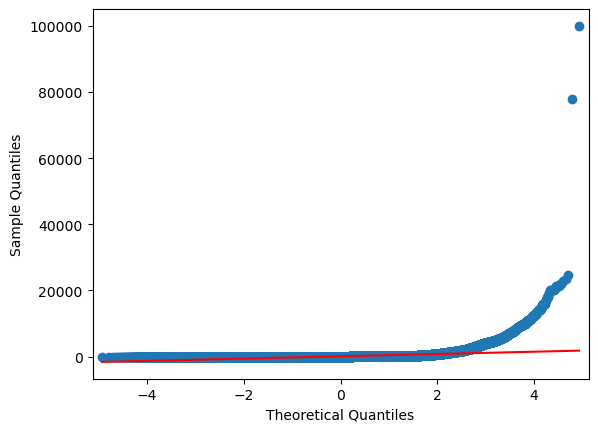

In [369]:
import statsmodels.api as sm
sm.qqplot(df['price'], line='s');

In the lower tail (left side of the plot) and central portion, the data points is aligned with the red line. This indicates that the distribution of price follows the normal distribution.
Upper Tail: In the upper tail (right side of the plot), the data points deviate significantly from the red line, suggesting a long tail or skewness to the right. This indicates that there are more extreme high values in price than would be expected in a normal distribution.